In [1]:
import rioxarray
import matplotlib.pyplot as plt
import xarray as xr
import numpy as np
import torch
import pandas as pd
import os
import math
from tqdm import tqdm

data_dir = f"../Data/Dataset/"
mask_path = "../Data/Dataset/LDAPS.land_mask_only.nc"

#pred = np.load(f"{res_dir}/pred_{tag}.npy")
#true = np.load(f"{res_dir}/true_{tag}.npy")
ms = xr.open_dataset(mask_path)  # (731, 430)
mask = np.squeeze(ms['mask'].values)
land_mask = mask.astype("float32")

lat= ms['latitude'].values
lon= ms['longitude'].values
# 위경도 범위 및 해상도
lat_min, lat_max = 33, 43
lon_min, lon_max = 124, 131

height = 731
width = 430

# extent 설정 (lon_min, lon_max, lat_min, lat_max)
extent = [lon_min, lon_max, lat_min, lat_max]

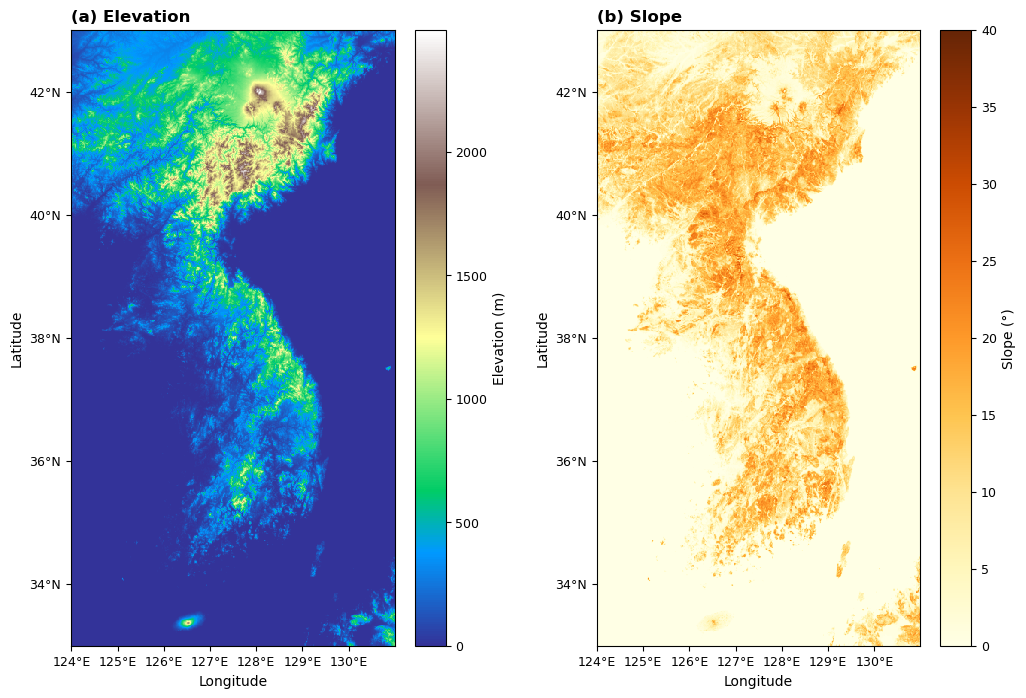

In [11]:
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np
from matplotlib.ticker import FuncFormatter

def _fmt_lon(x, _):
    return f"{x:.0f}°E" if x >= 0 else f"{-x:.0f}°W"

def _fmt_lat(y, _):
    return f"{y:.0f}°N" if y >= 0 else f"{-y:.0f}°S"

# ── 데이터 로드 ──────────────────────────────────────────────
ds_elev  = xr.open_dataset("./Dataset/elevation.res_1.5km.nc")
ds_slope = xr.open_dataset("./Dataset/slope.res_1.5km.nc")

elev  = ds_elev["elevation"]
slope = ds_slope["slope"].where(ds_slope["slope"] != -9999)

# ── 그림 ─────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 8),
                         gridspec_kw={"wspace": 0.3})

panels = [
    (elev,  "(a) Elevation", "terrain",     {"vmin": 0},        "Elevation (m)"),
    (slope, "(b) Slope",     "YlOrBr",      {"vmin": 0, "vmax": 40}, "Slope (°)"),
]

for ax, (data, title, cmap, kwargs, cbar_label) in zip(axes, panels):
    im = data.plot(
        ax=ax,
        cmap=cmap,
        add_colorbar=False,   # colorbar 직접 추가
        **kwargs,
    )
    cb = plt.colorbar(im, ax=ax, pad=0.05)
    cb.set_label(cbar_label, fontsize=10)
    cb.ax.tick_params(labelsize=9)

    ax.set_title(title, fontsize=12, fontweight="bold", pad=6, loc="left")
    ax.set_ylabel("Latitude",  fontsize=10)
    ax.set_xlabel("Longitude", fontsize=10)
    ax.xaxis.set_major_formatter(FuncFormatter(_fmt_lon))
    ax.yaxis.set_major_formatter(FuncFormatter(_fmt_lat))
    ax.tick_params(labelsize=9)




plt.show()

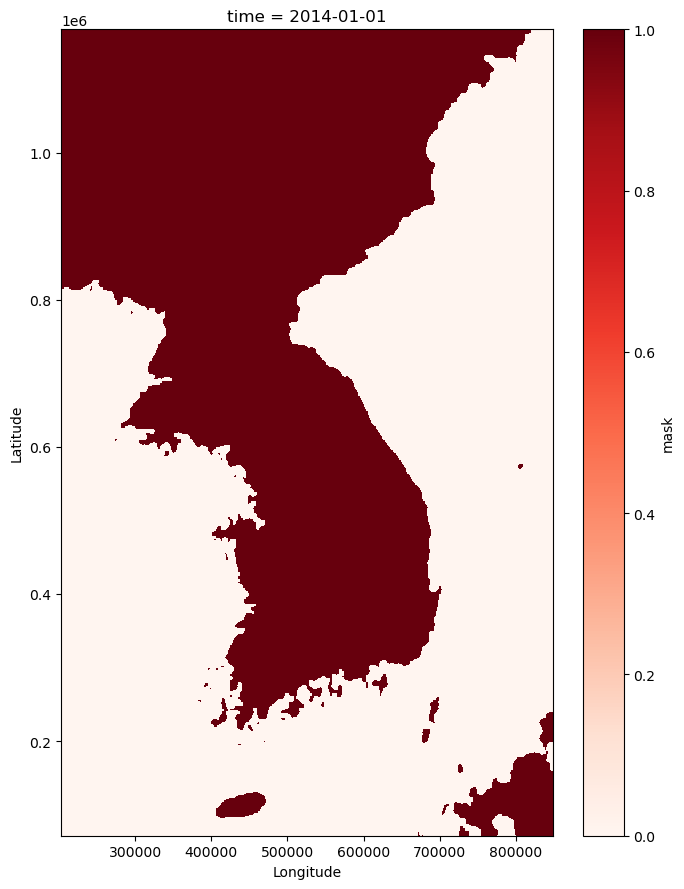

In [2]:
# 고도 데이터 열기
mass = ms["mask"]  # 변수 이름이 뭔지 모를 때 첫 변수 자동 선택

mass = mass.where(np.isfinite(mass))

# 그림 그리기
plt.figure(figsize=(7, 9))
mass.plot(cmap="Reds")
#plt.title("Copernicus 90m Elevation")
plt.xlabel("Longitude")

plt.ylabel("Latitude")
plt.tight_layout()
plt.show()

# 0. Data visualization (Topography)

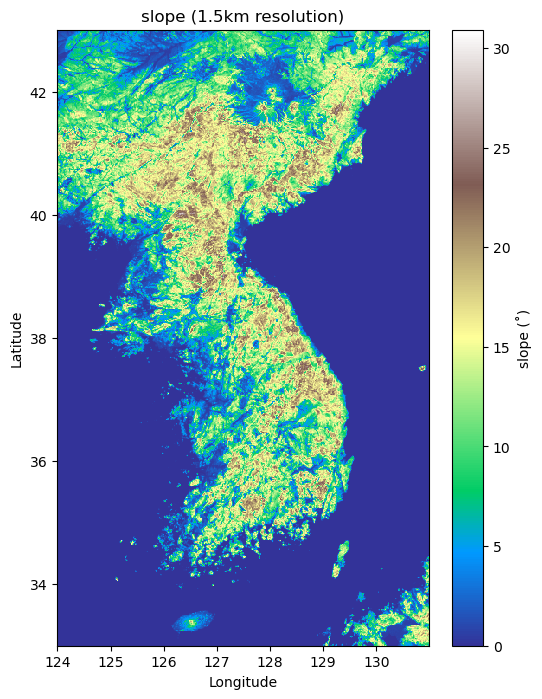

NameError: name 'slope' is not defined

In [ ]:
# 1. 파일 열기

var = "slope"
ds = xr.open_dataset(f"./Dataset/{var}.res_1.5km.nc")

# 3. 예시: 변수명이 '{}}'이라고 가정
elev = ds[var]  # 필요시 ds.data_vars.keys()로 정확한 이름 확인 가능

# 4. 그림 그리기
plt.figure(figsize=(6, 8))
elev.plot(cmap="terrain", cbar_kwargs={"label": f"{var} (˚)"}, vmin=0)#, vmax=45, vmin=0)
plt.title(f"{var} (1.5km resolution)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()

  
slope = slope.where(slope != -9999)
# 시각화
plt.figure(figsize=(6, 8))
slope.plot(cmap="terrain", vmin=0, vmax=45, cbar_kwargs={"label": "Slope (°)"})
plt.title("SRTM-1km Slope")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.tight_layout()
plt.show()


# 고도 데이터 열기
ds = xr.open_dataset("COP90m_cut.nc")
elev = ds["elevation"]  # 변수 이름이 뭔지 모를 때 첫 변수 자동 선택

# NoData가 있다면 마스킹 처리 (선택적)
elev = elev.where(np.isfinite(elev))

# 그림 그리기
plt.figure(figsize=(6, 8))
elev.plot(cmap="terrain", vmin=0, vmax=1500, cbar_kwargs={"label": "Elevation (m)"})
plt.title("Copernicus 90m Elevation")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.tight_layout()
plt.show()

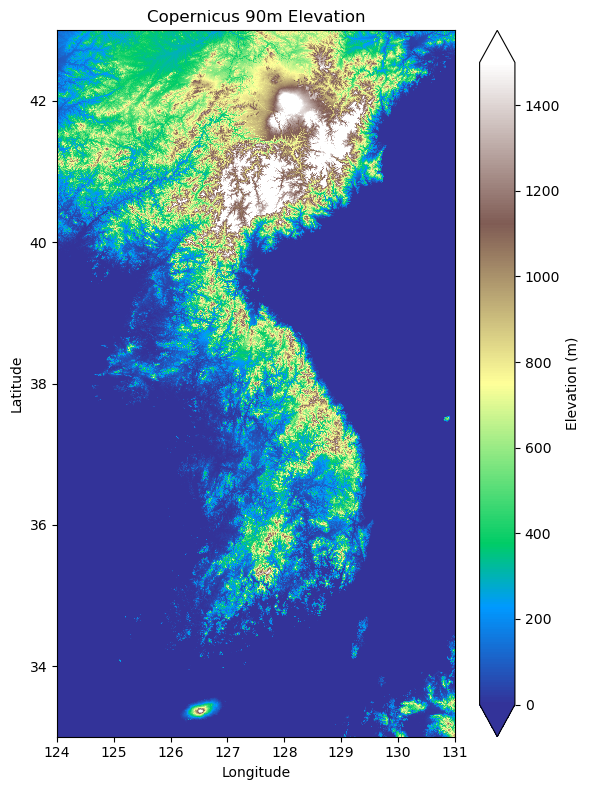

In [ ]:
# 고도 데이터 열기
ds = xr.open_dataset("COP90m_cut.nc")
elev = ds["elevation"]  # 변수 이름이 뭔지 모를 때 첫 변수 자동 선택

# NoData가 있다면 마스킹 처리 (선택적)
elev = elev.where(np.isfinite(elev))

# 그림 그리기
plt.figure(figsize=(6, 8))
elev.plot(cmap="terrain", vmin=0, vmax=1500, cbar_kwargs={"label": "Elevation (m)"})
plt.title("Copernicus 90m Elevation")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.tight_layout()
plt.show()

In [ ]:
ds = xr.open_dataset("./Dataset/ERA5.lai_climatology.nc")
lai = ds["lai"]  

fig = plt.figure(figsize=(6, 8))
ax = fig.add_subplot(111)
im = lai.plot(ax=ax, cmap="YlGn", cbar_kwargs={"label": "Leaf Area Index (m²/m²)"})
ax.set_axis_off()  # 축 꺼버리기
plt.tight_layout()
plt.show()


In [ ]:
var_name ="sp"

ds = xr.open_dataset(f"./Dataset/ERA5.{var_name}.2013-2024.nc")
lai = ds[var_name][-1]

fig = plt.figure(figsize=(6, 8))
ax = fig.add_subplot(111)
im = lai.plot(ax=ax, cmap="BrBG")
ax.set_axis_off()  # 축 꺼버리기
plt.tight_layout()
plt.show()


# 1. Data pre-processing

## 1.1 Topography

### Latitude, longitude radian conversion

In [ ]:
import xarray as xr
import torch
import numpy as np
import math

# =========================
# 함수 정의
# =========================
def normalize(x):
    """[-1, 1] 범위로 정규화"""
    xmin, xmax = np.nanmin(x), np.nanmax(x)
    return 2 * (x - xmin) / (xmax - xmin) - 1

def process_and_save_latlon(nc_path, lat_name, lon_name, save_path, desc):
    print(f"[INFO] Processing {desc}...")

    ds = xr.open_dataset(nc_path)
    lat = ds[lat_name].values.astype(np.float32)
    lon = ds[lon_name].values.astype(np.float32)

    # --- (1) Meshgrid 만들기 (ERA5의 경우)
    if lat.ndim == 1 and lon.ndim == 1:
        lon, lat = np.meshgrid(lon, lat, indexing="xy")

    # --- (2) degree → radian 변환 ---
    lat_rad = lat * (math.pi / 180.0)
    lon_rad = lon * (math.pi / 180.0)

    # --- (3) 표준화 (선택적으로 모델 입력 안정화 목적) ---
    lat_rad_norm = normalize(lat_rad)
    lon_rad_norm = normalize(lon_rad)

    # --- (4) (2, H, W) 텐서로 묶기 ---
    latlon_tensor = torch.from_numpy(np.stack([lat_rad_norm, lon_rad_norm], axis=0))

    # --- (5) 저장 ---
    torch.save(latlon_tensor, save_path)
    print(f"[OK] Saved: {save_path}  shape={tuple(latlon_tensor.shape)}")


# =========================
# ERA5 (Low-resolution)
# =========================


for res in ["0.5deg","1deg","2deg","3deg"]:
    process_and_save_latlon(
        nc_path=f"./Dataset/{res}/ERA5.t2m.2013-2024.nc",
        lat_name="lat",
        lon_name="lon",
        save_path=f"./Dataset/{res}/input_latlon_LR.pt",
    desc="ERA5 (Low-Resolution)"
    )

# =========================
# LDAPS (High-resolution)
# =========================
# process_and_save_latlon(
#     nc_path="./Dataset/LDAPS.land_mask_only.nc",
#     lat_name="latitude",
#     lon_name="longitude",
#     save_path="./Dataset/LDAPS_latlon_HR.pt",
#     desc="LDAPS (High-Resolution)"
# )

print("\n✅ All positional coordinate tensors ready! (radian, normalized)")


In [ ]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# ---------------------------
# 1) 파일 로드
# ---------------------------
lr_path = Path("./Dataset/0.2deg/input_latlon.pt")
hr_path = Path("./Dataset/target_latlon.pt")

lr = torch.load(lr_path)   # {'lat_deg','lon_deg','lat_rad','lon_rad'}
hr = torch.load(hr_path)

lat_lr = lr["lat_deg"].numpy()
lon_lr = lr["lon_deg"].numpy()
lat_hr = hr["lat_deg"].numpy()
lon_hr = hr["lon_deg"].numpy()

print("[LR] shape:", lat_lr.shape, lon_lr.shape)
print("[HR] shape:", lat_hr.shape, lon_hr.shape)

# ---------------------------
# 2) 도메인 범위 및 일치 여부 확인
# ---------------------------
def extent(lat, lon):
    return (float(lat.min()), float(lat.max()), float(lon.min()), float(lon.max()))

latlr_min, latlr_max, lonlr_min, lonlr_max = extent(lat_lr, lon_lr)
lathr_min, lathr_max, lonhr_min, lonhr_max = extent(lat_hr, lon_hr)

print(f"[LR extent] lat [{latlr_min:.3f}, {latlr_max:.3f}], lon [{lonlr_min:.3f}, {lonlr_max:.3f}]")
print(f"[HR extent] lat [{lathr_min:.3f}, {lathr_max:.3f}], lon [{lonhr_min:.3f}, {lonhr_max:.3f}]")

# ---------------------------
# 3) 그리드 빠른 프리뷰 (산점도)
#    - HR은 점이 많으니 다운샘플링해서 표시
# ---------------------------
def plot_grid_scatter(lat, lon, title, step=1, marker='.', s=4, alpha=1.0):
    y = lat[::step, ::step].ravel()
    x = lon[::step, ::step].ravel()
    plt.figure()
    plt.scatter(x, y, marker=marker, s=s, alpha=alpha)
    plt.xlabel("Longitude (deg)")
    plt.ylabel("Latitude (deg)")
    plt.title(title)
    plt.gca().set_aspect('equal', adjustable='box')
    plt.grid(True)
    plt.tight_layout()

# (A) LR 그리드 점 위치
plot_grid_scatter(lat_lr, lon_lr, "ERA5 LR grid (points)", step=1, s=20)

# (B) HR 그리드 점 위치 (다운샘플 예: 10칸마다 한 점)
plot_grid_scatter(lat_hr, lon_hr, "LDAPS HR grid (points, downsampled)", step=10, s=4, alpha=0.7)

# ---------------------------
# 4) LR vs HR 도메인 겹침 확인 (같은 플롯에 오버레이)
# ---------------------------
plt.figure()
# HR을 먼저 옅게 뿌리고
x_hr = lon_hr[::10, ::10].ravel()
y_hr = lat_hr[::10, ::10].ravel()
plt.scatter(x_hr, y_hr, s=3, alpha=0.4, label="HR (downsample)")

# LR을 진하게 찍어서 겹침 느낌 확인
x_lr = lon_lr.ravel()
y_lr = lat_lr.ravel()
plt.scatter(x_lr, y_lr, s=30, alpha=1.0, label="LR")

plt.xlabel("Longitude (deg)")
plt.ylabel("Latitude (deg)")
plt.title("Overlay: LR vs HR grids")
plt.gca().set_aspect('equal', adjustable='box')
plt.grid(True)
plt.legend()
plt.tight_layout()

# ---------------------------
# 5) 메시 셀 느낌 보기 (pcolormesh로 위도값 컬러맵)
#    - 색은 따로 지정하지 않음(기본값)
# ---------------------------
plt.figure()
plt.pcolormesh(lon_lr, lat_lr, lat_lr, shading="auto")
plt.xlabel("Longitude (deg)")
plt.ylabel("Latitude (deg)")
plt.title("ERA5 LR grid cells (pcolormesh of latitude)")
plt.gca().set_aspect('equal', adjustable='box')
plt.tight_layout()

# ---------------------------
# 6) 저장(옵션)
# ---------------------------
outdir = Path("./_quicklooks")
outdir.mkdir(parents=True, exist_ok=True)
for i, fig in enumerate(map(plt.figure, plt.get_fignums())):
    fig.savefig(outdir / f"latlon_preview_{i+1}.png", dpi=150)

plt.show()


### LAI index

In [ ]:
def preprocess_lai_climatology_by_resolution(
    resolutions: list,
    base_dir: str = "./Dataset/"
):
    for res in resolutions:
        print(f"\n🌿 Processing LAI climatology for {res}deg")

        res_dir = os.path.join(base_dir, f"{res}deg")
        file_path = os.path.join(res_dir, "ERA5.lai_climatology.nc")

        if not os.path.exists(file_path):
            print(f"❌ File not found: {file_path}")
            continue

        # Open and extract variable
        ds = xr.open_dataset(file_path)
        lai = ds['lai'] 
        ny, nx = lai.shape

        # 2. NaN mask 판단
        lai_flat = lai.values.reshape(-1)  # (lat * lon,)
        if np.isnan(lai_flat).any():
            valid_mask = ~np.isnan(lai_flat)
            print(f"⚠️  Found NaNs — removing {np.sum(~valid_mask)} grid points.")

            n_valid = valid_mask.sum()
            lat_new = int(np.floor(np.sqrt(n_valid)))
            lon_new = int(n_valid // lat_new)

            lai_valid = lai_flat[valid_mask]
            lai_reshaped = lai_valid[:lat_new * lon_new].reshape(lat_new, lon_new)
        else:
            print("✅ No NaNs — using full grid.")
            lai_reshaped = lai.values

        # Mean & std
        mean = lai_reshaped.mean()
        std = lai_reshaped.std()
        lai_norm = (lai_reshaped - mean) / std

        # Save
        torch.save(torch.from_numpy(lai_norm.astype("float32")),
                   os.path.join(res_dir, "input_lai_data.pt"))
        torch.save({"mean": mean.item(), "std": std.item()},
                   os.path.join(res_dir, "input_lai_stats.pt"))

        print(f"✅ Saved to {res_dir}: input_lai_data.pt + input_lai_clim_stats.pt")

preprocess_lai_climatology_by_resolution( resolutions=['3'] )


### Elevation + slope

In [ ]:
base_dir="./Dataset"
topo_files={"elevation": "elevation.res_1.5km.nc", "slope": "slope.res_1.5km.nc"}

torch.save(torch.from_numpy(land_mask), os.path.join(base_dir, "input_LDAPS_landmask_data.pt"))
print("✅ Saved: input_LDAPS_landmask_data.pt")

# 🔹 고도/경사도 전처리
for var_name, filename in topo_files.items():
    file_path = os.path.join(base_dir, filename)
    print(f"\n⛰️  Processing {var_name}...")

    if not os.path.exists(file_path):
        print(f"❌ File not found: {file_path}")
        continue

    ds = xr.open_dataset(file_path)
    da = ds[var_name]

    if da.shape != land_mask.shape:
        raise ValueError(f"Shape mismatch: {da.shape} vs {land_mask.shape}")

    # 육지만 사용해 평균, 표준편차 계산
    da_land = da.where(land_mask == 1)
    mean = da_land.mean(skipna=True).item()
    std = da_land.std(skipna=True).item()

    # 정규화: 전체 격자에 대해 적용, 바다는 0으로 overwrite
    da_norm = (da - mean) / std
    da_norm = da_norm.where(land_mask == 1, 0)  # 바다는 0으로 설정

    # 저장
    torch.save(torch.from_numpy(da_norm.values.astype("float32")),
               os.path.join(base_dir, f"input_{var_name}_data.pt"))
    torch.save({"mean": mean, "std": std},
               os.path.join(base_dir, f"{var_name}_stats.pt"))

    print(f"✅ Saved: input_{var_name}_data.pt / {var_name}_stats.pt")

#### Masking invalid elevation values

In [ ]:
import torch
import xarray as xr
import numpy as np
import os

# =========================================================
# 설정
# =========================================================
base_dir = "./Dataset"  # 데이터 폴더 경로
topo_files = {
    "elevation": "elevation.res_1.5km.nc", 
    "slope": "slope.res_1.5km.nc"
}
# Land Mask 파일 경로 (바다=NaN 또는 0, 육지=1로 되어있는 파일)
mask_filename = "LDAPS.land_mask_only.nc"  # 실제 파일명 확인 필요

# =========================================================
# 1. Land Mask 로드 및 저장
# =========================================================
mask_path = os.path.join(base_dir, mask_filename)
if not os.path.exists(mask_path):
    raise FileNotFoundError(f"Mask file not found: {mask_path}")

ds_mask = xr.open_dataset(mask_path)
# 변수명이 'mask', 'landmask', 'lsm' 등일 수 있으니 확인
mask_var = list(ds_mask.data_vars)[0] 
land_mask = ds_mask[mask_var].values  # (H, W)
land_mask = np.nan_to_num(land_mask, nan=0.0) # 혹시 NaN 있으면 0으로

land_mask = land_mask.squeeze(0)



# =========================================================
# 2. 고도/경사도 전처리 (핵심 수정 부분)
# =========================================================
for var_name, filename in topo_files.items():
    file_path = os.path.join(base_dir, filename)
    print(f"\n⛰️  Processing {var_name}...")

    if not os.path.exists(file_path):
        print(f"❌ File not found: {file_path}")
        continue

    ds = xr.open_dataset(file_path)
    var_key = list(ds.data_vars)[0]
    da = ds[var_key]

    if da.shape != land_mask.shape:
        # 쉐이프가 다르면 자르거나 맞춰야 함 (여기선 에러 발생)
        raise ValueError(f"Shape mismatch: {da.shape} vs {land_mask.shape}")

    # ---------------------------------------------------------
    # [Step 1] 육지 통계 계산 (Mean, Std)
    # 바다는 제외하고, 육지의 특성만 반영하기 위해 마스킹 후 계산
    # ---------------------------------------------------------
    da_land = da.where(land_mask == 1)
    mean = da_land.mean(skipna=True).item()
    std = da_land.std(skipna=True).item()
    
    print(f"   -> Land Mean: {mean:.4f}, Land Std: {std:.4f}")

    # ---------------------------------------------------------
    # [Step 2] 바다(NaN)를 물리적 0값으로 채움
    # 고도 0m, 경사도 0도
    # ---------------------------------------------------------
    da_filled = da.fillna(0.0) 

    # ---------------------------------------------------------
    # [Step 3] 정규화 (Normalization) - 바다 포함 전체 적용!
    # 핵심: 바다(0)에서 육지 평균(mean)을 빼면 음수(-)가 됨.
    # 예: (0 - 400) / 400 = -1.0
    # 결과: 바다(-1.0) < 평야(-0.9) < 산(+2.0) 순서가 올바르게 잡힘.
    # ---------------------------------------------------------
    da_norm = (da_filled - mean) / std
    
    # ⚠️ 주의: 여기서 다시 where(mask, 0)을 하면 안 됨! 그대로 저장.

    # ---------------------------------------------------------
    # [Step 4] 저장
    # ---------------------------------------------------------
    # Tensor 변환
    tensor_norm = torch.from_numpy(da_norm.values.astype("float32"))
    
    # 데이터 저장
    save_path_data = os.path.join(base_dir, f"X_{var_name}_data.pt")
    torch.save(tensor_norm, save_path_data)
    
    # 통계 저장
    save_path_stats = os.path.join(base_dir, f"X_{var_name}_stats.pt")
    torch.save({"mean": mean, "std": std}, save_path_stats)

    print(f"✅ Saved: {save_path_data}")
    print(f"   (Stats saved to {save_path_stats})")
    
    # 확인용 출력 (바다 값 확인)
    # 바다 영역(land_mask==0)의 평균값이 음수인지 확인
    sea_val_mean = tensor_norm[land_mask == 0].mean().item()
    print(f"   -> Check Sea Value (Should be negative): {sea_val_mean:.4f}")

#### Super-pixcel try

In [ ]:
from skimage.segmentation import slic, mark_boundaries

# 1. 정규화된 고도 / 경사 데이터 불러오기
elev = torch.load("./Dataset/input_elevation_data.pt").numpy()   # shape: (H, W)
slope = torch.load("./Dataset/input_slope_data.pt").numpy()      # shape: (H, W)

# 2. 두 개 결합해서 (H, W, 2) 이미지처럼 만듦
img = np.stack([elev, slope], axis=-1)  # shape: (731, 430, 2)

# 3. SLIC super-pixel segmentation
segment_map = slic(img, n_segments=1000, compactness=3, start_label=0, channel_axis=-1)

# 4. 시각화를 위해 경계 표시 (elevation 기준 시각화)
boundary_img = mark_boundaries(elev, segment_map)

# 5. 시각화
plt.figure(figsize=(8, 10))
plt.imshow(boundary_img, cmap='magma',origin="lower")
plt.title("Super-pixel Segmentation (SLIC)\nBase: Elevation + Slope", fontsize=14)
plt.axis("off")
plt.tight_layout()
plt.show()

# 6. 저장 (선택)
#np.save("segment_map_300.npy", segment_map.astype(np.int32))


## 1.2 Input Dynamic variable

### ERA5 data 전처리 함수 (Residual Pattern)

In [ ]:
"""
ERA5 전처리 (전체 기간 기준 global scaling, detrend 없음)
- 타깃(예: t2m, anomaly=True):
  1) 계절성 제거 (DOY climatology)
  2) 평균 공간 패턴/도메인 평균 시계열 분리(S', A', μ')
  3) Residual R' = X0 - S' - A' - μ'
  4) 전체 기간 기준 global mean/std 로 스케일링 (면적가중/육지마스크 옵션)
- 보조 동적변수(anomaly=False): 변수별 전체 기간 기준 global z-score

주의:
- 모든 통계는 **전체 기간**으로 계산.
- detrend(격자별 선형 추세 제거)는 수행 X.
- 마스크가 있으면 mask==1 위치만 통계에 사용하며, 저장 텐서는 원격자 형태 유지.
"""

# -------------------- 유틸 --------------------
def _make_area_weights(lat):
    """cos(lat) 가중치 – 1D(lat)로만 생성 (브로드캐스트 안정)"""
    w = np.cos(np.deg2rad(lat.values))
    w = w / np.nanmean(w)
    return xr.DataArray(w, coords={"latitude": lat}, dims=("latitude",))  # ✅ 1D만!


def _apply_mask(da, mask):
    """mask==1(유효/육지)만 사용. mask=None이면 원본 반환.
    mask shape=(latitude,longitude)
    """
    if mask is None:
        return da
    mask_da = xr.DataArray(mask, coords={"latitude": da.latitude, "longitude": da.longitude}, dims=("latitude","longitude"))
    return da.where(mask_da == 1)


def _global_mean_std(da, weights=None, eps=1e-8):
    """시간·공간 전체(global) mean/std. (time, lat, lon)
    weights: (lat,lon) 면적가중. None이면 비가중.
    반환: (mu, std) 파이썬 float
    """
    
    if weights is not None:
        w = weights
        w3 = w.broadcast_like(da.isel(time=0))
        w3 = xr.concat([w3] * da.sizes["time"], dim="time")
        w3["time"] = da.time

        num = (da * w3).sum(dim=("time","latitude","longitude"), skipna=True)
        den = w3.where(np.isfinite(da)).sum(dim=("time","latitude","longitude"), skipna=True)
        mu = num / den

        var_num = ((da - mu) ** 2 * w3).sum(dim=("time","latitude","longitude"), skipna=True)
        var = var_num / den
        std = np.sqrt(var + eps)
        return float(mu.values), float(std.values)
    else:
        mu = float(da.mean(dim=("time","latitude","longitude"), skipna=True).values)
        std = float(da.std(dim=("time","latitude","longitude"), skipna=True).values + 1e-6)
        return mu, std

def sdoy_anomaly(da: xr.DataArray, window: int = 31) -> tuple[xr.DataArray, xr.DataArray]:
    assert "time" in da.dims
    assert window % 2 == 1

    time_len = da.sizes["time"]
    half_win = window // 2
    
    # 1) wrap pad 후 rolling mean
    pad = da.pad(time=(half_win, half_win), mode="wrap")
    roll_da = pad.rolling(time=window, center=True).mean()
    roll_da = roll_da.isel(time=slice(half_win, half_win + time_len))

    # 2) '월-일' 라벨 부여(윤년 포함시 02-29도 별도 라벨)
    dates = pd.to_datetime(da.time.values)
    month_day = np.array([f"{d.month:02d}-{d.day:02d}" for d in dates], dtype="U5")

    # 3) 달력 날짜별 평균 → smoothed climatology
    roll_da = roll_da.assign_coords(month_day=("time", month_day))
    clim_smooth = roll_da.groupby("month_day").mean("time", skipna=True)
    
    # 4) anomaly: 각 time의 month_day로 매칭
    clim_match = clim_smooth.sel(month_day=xr.DataArray(month_day, dims="time"))
    X0 = da - clim_match
    return clim_smooth, X0

# -------------------- 메인 전처리 --------------------
def preprocess_inputs_ERA5(
    variable_config: dict,
    resolutions: list,
    base_dir: str = "./Dataset/",
    time_range: str = "2013-2024",
    area_weighted: bool = True,
    land_mask_path: bool = None,
    sdoy_window: int = 31
):
    """
    variable_config 예시
    {
      "t2m": {"anomaly": True},    # HR Residual 패턴으로 만들 메인 입력 변수 (LR residual)
      "u10": {"anomaly": False},   # 보조 동적 입력
      "v10": {"anomaly": False},
      "sp":  {"anomaly": False},
    }
    """
    # 마스크 로드(선택)
    land_mask = None
    if land_mask_path and os.path.exists(land_mask_path):
        if land_mask_path.endswith(".pt"):
            land_mask = torch.load(land_mask_path)
            land_mask = land_mask.cpu().numpy().astype(np.float32)
        else:
            land_mask = np.load(land_mask_path).astype(np.float32)


    for res in resolutions:
        print(f"🔧 [Resolution: {res}deg]")
        res_dir = os.path.join(base_dir, f"{res}deg")
        os.makedirs(res_dir, exist_ok=True)

        stats_all = {}

        for var_name, conf in variable_config.items():
            nc_path = os.path.join(res_dir, f"ERA5.{var_name}.{time_range}.nc")
            if not os.path.exists(nc_path):
                print(f"❌ {nc_path} not found. Skipping...")
                continue

            ds = xr.open_dataset(nc_path)
            if "valid_time" in ds.dims:
                ds = ds.rename({"valid_time": "time"})
            da = ds[var_name]  # (time, lat, lon)
            da = da.sortby("time")

            # 면적가중/마스크 준비
            w = _make_area_weights(da.latitude) if area_weighted else None
            use_mask = bool(conf.get("use_mask", False))  # 기본 False
            da_all = _apply_mask(da, land_mask) if use_mask else da

            is_anom = bool(conf.get("anomaly", False))
            print(f"📦 Processing {var_name}  (anomaly={is_anom})")

            if is_anom:
                # === (anomaly=True) sDOY 사용 ===
                clim, X0 = sdoy_anomaly(da_all, window= sdoy_window)  # default는 31일 (원하면 conf로 받기)

                # μ', S'(x,y), A'(t) 계산
                mu_prime = float(X0.mean(dim=("time","latitude","longitude"), skipna=True).values)
                S_bar = X0.mean(dim="time", skipna=True)                 # (latitude,longitude)
                S_prime = S_bar - mu_prime                               # (latitude,longitude)

                # 도메인 평균 시계열 (면적가중 옵션)
                if w is not None:
                    w2 = w.broadcast_like(S_bar)
                    A_series = (X0 * w2).sum(dim=("latitude","longitude"), skipna=True) / w2.where(np.isfinite(X0)).sum(dim=("latitude","longitude"), skipna=True)
                else:
                    A_series = X0.mean(dim=("latitude","longitude"), skipna=True)
                A_prime = A_series - mu_prime                            # (time,)
                A_field = A_prime.broadcast_like(X0)                     # (time,lat,lon)

                # Residual
                R = X0 - S_prime - A_field - mu_prime

                # 전체 기간 기준 global z-score (면적가중은 선택)
                mu_g, std_g = _global_mean_std(R, weights=w)
                Rn = (R - mu_g) / std_g

                # 통계 저장(복원용)
                stats_all[var_name] = {
                    "mu_global": torch.tensor(mu_g, dtype=torch.float32),
                    "std_global": torch.tensor(std_g, dtype=torch.float32),
                    "mu_prime":  torch.tensor(mu_prime, dtype=torch.float32),
                    "clim":      torch.from_numpy(clim.values.astype(np.float32)),     # (<=366, lat, lon) with month_day
                    "S_prime":   torch.from_numpy(S_prime.values.astype(np.float32)),  # (lat,lon)
                }
                out = Rn

            else:
                # 보조 동적 변수: 변수별 전체기간 global z-score
                mu_g, std_g = _global_mean_std(da_all, weights=w)
                out = (da_all - mu_g) / std_g
                stats_all[var_name] = {
                    "mu_global": torch.tensor(mu_g, dtype=torch.float32),
                    "std_global": torch.tensor(std_g, dtype=torch.float32),
                }

            # === 저장 ===
            arr = torch.from_numpy(out.values.astype(np.float32))
            torch.save(arr, os.path.join(res_dir, f"input_{var_name}_data_residual.pt"))
            ds.close()
            print(f"✅ Saved: input_{var_name}_data_residual.pt  shape={tuple(arr.shape)}")

        # 공통 통계 저장
        torch.save(stats_all, os.path.join(res_dir, "input_climstats_residual.pt"))
        print(f"📝 Saved stats: {os.path.join(res_dir, 'input_climstats_residual.pt')}")

    print("🎉 모든 변수 전처리 완료! (전체 기간 기준, detrend 없음, static 제외)")

In [ ]:
variable_config = {
    "t2m": {"anomaly": True},   # 메인 LR Residual T  변수
    "u10": {"anomaly": False},  # 보조 입력
    "v10": {"anomaly": False},
    "sp":  {"anomaly": False}}

preprocess_inputs_ERA5(
    variable_config=variable_config,
    resolutions=["0.2"],             # ERA5 해상도 (네가 가진 데이터 폴더 구조에 맞춰)
    base_dir="./Dataset/",            # 데이터 저장 디렉토리
    time_range="2013-2024",          # 파일명에 들어간 기간
    area_weighted=True,               # 면적가중 μ/σ 
    land_mask_path=None,             # 육지 마스크  (Input은 필요 없음)
    sdoy_window=31                    # sDOY window 크기 (보통 21~31일)
)

In [ ]:
# 교수님과 말한 최종 방식의 데이터 전처리 방식

# -------------------- 유틸 --------------------

def _make_area_weights(lat_coord, lat_name):
    """cos(lat) 가중치 – 1D(lat)로만 생성 (브로드캐스트 안정)"""
    # 인자로 위도 좌표(lat_coord)와 차원 이름(lat_name)을 받음
    w = np.cos(np.deg2rad(lat_coord.values))
    w = w / np.nanmean(w)
    # 하드코딩된 "latitude" 대신 동적 차원 이름(lat_name) 사용
    return xr.DataArray(w, coords={lat_name: lat_coord}, dims=(lat_name,))

def _apply_mask(da, mask, lat_name, lon_name):
    """mask==1(유효/육지)만 사용. mask=None이면 원본 반환."""
    # 인자로 위도/경도 차원 이름(lat_name, lon_name)을 받음
    if mask is None:
        return da
    mask_da = xr.DataArray(
        mask, 
        # 하드코딩된 이름 대신 da[lat_name], da[lon_name] 사용
        coords={lat_name: da[lat_name], lon_name: da[lon_name]},
        dims=(lat_name, lon_name)
    )
    return da.where(mask_da == 1)

def _global_mean_std(da, lat_name, lon_name, weights=None, eps=1e-8):
    """시간·공간 전체(global) mean/std. (time, lat, lon) -> (float, float)"""
    # 인자로 위도/경도 차원 이름(lat_name, lon_name)을 받음
    spatial_dims = (lat_name, lon_name)
    all_dims = ("time",) + spatial_dims

    if weights is not None:
        # weights: (lat), broadcast to (time, lat, lon)
        w2 = weights.broadcast_like(da.isel(time=0))            # (lat,lon)
        w3 = xr.concat([w2]*da.sizes["time"], dim="time")       # (time,lat,lon)
        w3["time"] = da.time

        # 하드코딩된 ("time","latitude","longitude") 대신 all_dims 사용
        num = (da * w3).sum(all_dims, skipna=True)
        den = w3.where(np.isfinite(da)).sum(all_dims, skipna=True)
        mu = num / (den + eps)

        var_num = ((da - mu)**2 * w3).sum(all_dims, skipna=True)
        var = var_num / (den + eps)
        std = np.sqrt(var + eps)
        return float(mu.values), float(std.values)
    else:
        # 하드코딩된 ("time","latitude","longitude") 대신 all_dims 사용
        mu = float(da.mean(all_dims, skipna=True).values)
        std = float(da.std(all_dims, skipna=True).values + 1e-6)
        return mu, std

def sdoy_anomaly(da: xr.DataArray, window: int = 31) -> tuple[xr.DataArray, xr.DataArray]:
    """sDOY(가변 창) climatology와 anomaly(T - clim) 반환 (이 함수는 수정 필요 없음)"""
    assert "time" in da.dims and window % 2 == 1
    time_len = da.sizes["time"]; half = window // 2

    pad = da.pad(time=(half, half), mode="wrap")
    roll = pad.rolling(time=window, center=True).mean()
    roll = roll.isel(time=slice(half, half + time_len))

    dates = pd.to_datetime(da.time.values)
    month_day = np.array([f"{d.month:02d}-{d.day:02d}" for d in dates], dtype="U5")
    roll = roll.assign_coords(month_day=("time", month_day))
    clim = roll.groupby("month_day").mean("time", skipna=True)

    clim_match = clim.sel(month_day=xr.DataArray(month_day, dims="time"))
    X0 = da - clim_match  # T'
    return clim, X0

# -------------------- 메인 전처리 (최종 방식 반영, 수정됨) --------------------
def preprocess_inputs_ERA5(
    variable_config: dict,
    resolutions: list,
    base_dir: str = "./Dataset/",
    time_range: str = "2013-2024",
    area_weighted: bool = True,
    land_mask_path: str = None,
    sdoy_window: int = 31
):
    """
    variable_config 예시
    ... (주석 동일) ...
    """
    # 마스크 로드(선택)
    land_mask = None
    if land_mask_path and os.path.exists(land_mask_path):
        land_mask = torch.load(land_mask_path).cpu().numpy().astype(np.float32) \
                    if land_mask_path.endswith(".pt") else np.load(land_mask_path).astype(np.float32)

    for res in resolutions:
        print(f"🔧 [Resolution: {res}deg]")
        res_dir = os.path.join(base_dir, f"{res}deg")
        os.makedirs(res_dir, exist_ok=True)

        stats_all = {}

        for var_name, conf in variable_config.items():
            nc_path = os.path.join(res_dir, f"ERA5.{var_name}.{time_range}.nc")
            if not os.path.exists(nc_path):
                print(f"❌ {nc_path} not found. Skipping...")
                continue

            ds = xr.open_dataset(nc_path)
            if "t" in ds:
                ds = ds.rename({"t": var_name})
            if "valid_time" in ds.dims:
                ds = ds.rename({"valid_time": "time"})
            da = ds[var_name].sortby("time")  # (time, lat, lon)

            # --- [추가됨] 위도/경도 차원 이름 동적 탐지 ---
            if "latitude" in da.coords:
                lat_name = "latitude"
            elif "lat" in da.coords:
                lat_name = "lat"
            else:
                raise ValueError(f"Could not find latitude dimension in DataArray for {var_name}")

            if "longitude" in da.coords:
                lon_name = "longitude"
            elif "lon" in da.coords:
                lon_name = "lon"
            else:
                raise ValueError(f"Could not find longitude dimension in DataArray for {var_name}")
            
            spatial_dims = (lat_name, lon_name)
            # --- [추가 완료] ---


            # 면적가중/마스크 준비
            # _make_area_weights 호출 시 da[lat_name]과 lat_name 전달
            w_lat = _make_area_weights(da[lat_name], lat_name) if area_weighted else None
            use_mask = bool(conf.get("use_mask", False))
            # _apply_mask 호출 시 lat_name, lon_name 전달
            da_for_stats = _apply_mask(da, land_mask, lat_name, lon_name) if use_mask else da

            is_anom = bool(conf.get("anomaly", False))
            time_da = da["time"].compute()
            time_str = [pd.Timestamp(t).strftime("%Y-%m-%d") for t in pd.to_datetime(time_da.values)]
            print(f"📦 Processing {var_name}  (anomaly={is_anom})")

            if is_anom:
                # === 1) sDOY climatology 제거: T' = T - Tbar(x,y,sDOY) ===
                clim, Tprime = sdoy_anomaly(da_for_stats, window=sdoy_window)  # (<=366, y, x), (t, y, x)

                # === 2) 시점별 도메인 평균 제거: R = T' - <T'>_domain(t) ===
                if w_lat is not None:
                    w2 = w_lat.broadcast_like(Tprime.isel(time=0))  # (lat,lon)
                    # 하드코딩된 ("latitude","longitude") 대신 spatial_dims 사용
                    dom_mean_t = (Tprime * w2).sum(spatial_dims, skipna=True) / \
                                 w2.where(np.isfinite(Tprime)).sum(spatial_dims, skipna=True)
                else:
                    # 하드코딩된 ("latitude","longitude") 대신 spatial_dims 사용
                    dom_mean_t = Tprime.mean(spatial_dims, skipna=True)  # (time,)

                R = Tprime - dom_mean_t.broadcast_like(Tprime)  # (time,lat,lon)

                # === 3) 전체 기간 기준 global z-score (면적가중 옵션) ===
                # _global_mean_std 호출 시 lat_name, lon_name 전달
                mu_g, std_g = _global_mean_std(R, lat_name, lon_name, weights=w_lat)
                Rn = (R - mu_g) / std_g

                # === 4) 저장 및 통계 ===
                arr = torch.from_numpy(Rn.values.astype(np.float32))
                torch.save(arr, os.path.join(res_dir, f"input_{var_name}_data_residual_f.pt"))
                stats_all[var_name] = {
                    "mu_global": torch.tensor(mu_g, dtype=torch.float32),
                    "std_global": torch.tensor(std_g, dtype=torch.float32),
                    "clim_sdoy": torch.from_numpy(clim.values.astype(np.float32)),
                    "time_str": time_str,
                    "domain_mean": torch.from_numpy(dom_mean_t.compute().values.astype(np.float32))
                }
                print(f"✅ Saved: input_{var_name}_data_residual_f.pt  shape={tuple(arr.shape)}")

            else:
                # 보조 동적 변수: 변수별 전체기간 global z-score
                # _global_mean_std 호출 시 lat_name, lon_name 전달
                mu_g, std_g = _global_mean_std(da_for_stats, lat_name, lon_name, weights=w_lat)
                out = (da_for_stats - mu_g) / std_g

                arr = torch.from_numpy(out.values.astype(np.float32))
                torch.save(arr, os.path.join(res_dir, f"input_{var_name}_data_residual_f.pt"))
                stats_all[var_name] = {
                    "mu_global": torch.tensor(mu_g, dtype=torch.float32),
                    "std_global": torch.tensor(std_g, dtype=torch.float32),
                }
                print(f"✅ Saved: input_{var_name}_data_residual_f.pt  shape={tuple(arr.shape)}")

            ds.close()

        # 공통 통계 저장
        torch.save(stats_all, os.path.join(res_dir, "input_climstats_residual_f.pt"))
        print(f"📝 Saved stats: {os.path.join(res_dir, 'input_climstats_residual_f.pt')}")

    print("🎉 모든 변수 전처리 완료! ")

In [ ]:
# 1) 변수 설정
variable_config = {
    "t2m": {"anomaly": True, "use_mask": False},   # 교수님 방식 적용 (Residual 생성)
    "u10": {"anomaly": False, "use_mask": False}, 
    "v10": {"anomaly": False, "use_mask": False},
    "sp":  {"anomaly": False, "use_mask": False},
}

# 2) 해상도 리스트
resolutions = [0.5, 1]   # ERA5를 리샘플링한 해상도 목록

# 3) 실행
preprocess_inputs_ERA5(
    variable_config=variable_config,
    resolutions=resolutions,
    base_dir="./Dataset/",
    time_range="2013-2024",
    area_weighted=True,                     # cos(lat) 가중 평균 쓸지 여부
    land_mask_path=None, # 선택 (없으면 None)
    sdoy_window=31                          # sDOY climatology rolling window
)

In [ ]:
# 1) 변수 설정
variable_config = {
    "t925": {"anomaly": True, "use_mask": False},   # 교수님 방식 적용 (Residual 생성)
    "t850": {"anomaly": True, "use_mask": False}   
}

# 2) 해상도 리스트
resolutions = [0.2]   # ERA5를 리샘플링한 해상도 목록

# 3) 실행
preprocess_inputs_ERA5(
    variable_config=variable_config,
    resolutions=resolutions,
    base_dir="./Dataset/",
    time_range="2013-2024",
    area_weighted=True,                     # cos(lat) 가중 평균 쓸지 여부
    land_mask_path=None, # 선택 (없으면 None)
    sdoy_window=31                          # sDOY climatology rolling window
)


### LDAPS input data 전처리 함수 (Residual Pattern)

In [ ]:
# -------------------- 유틸 --------------------
def _global_mean_std_xy(da: xr.DataArray, eps: float = 1e-8):
    """비가중 global μ/σ in (time,y,x), NaN 무시는 skipna=True."""
    mu = float(da.mean(dim=("time","y","x"), skipna=True).values)
    std = float(da.std(dim=("time","y","x"), skipna=True).values + eps)
    return mu, std

def sdoy_anomaly_xy(da: xr.DataArray, window: int = 31):
    """
    sDOY climatology와 anomaly(X0) 계산 (time,y,x).
    return:
      - clim_smooth: (<=366, y, x) with coord 'month_day'
      - X0: (time, y, x)
      - month_day_seq: np.ndarray[str] length=T
    """
    assert "time" in da.dims, "DataArray must have time dim"
    assert window % 2 == 1, "sDOY window는 홀수 권장"
    T = da.sizes["time"]
    half = window // 2

    # 시간축 wrap-pad 후 rolling mean
    pad = da.pad(time=(half, half), mode="wrap")
    roll = pad.rolling(time=window, center=True).mean()
    roll = roll.isel(time=slice(half, half + T))  # 원래 길이 복원

    # month-day 라벨 생성
    dates = pd.to_datetime(da.time.values)
    month_day = np.array([f"{d.month:02d}-{d.day:02d}" for d in dates], dtype="U5")

    roll = roll.assign_coords(month_day=("time", month_day))
    clim = roll.groupby("month_day").mean("time", skipna=True)  # (<=366,y,x)

    # X0 = 원시값 - 같은 month-day climatology
    clim_match = clim.sel(month_day=xr.DataArray(month_day, dims="time"))
    X0 = da - clim_match
    return clim, X0, month_day

# -------------------- 메인 전처리 (마스킹 없음) --------------------
def preprocess_input_LDAPS_lowres_nomask(
    data_path: str,
    out_prefix: str,
    out_dir: str = "./Dataset/",
    var_name: str = "TMP_1D5maboveground",
    sdoy_window: int = 31,
    fill_nan_with: float = -999.0,
):
    """
    LDAPS 저해상도 입력 데이터에 대해 ERA5와 동일한 방식의 Residual(z-score) 전처리.
    - anomaly=True 변수처럼 처리 (항상 계절성 제거 후 residual 계산)
    - detrend 없음, mask 없음, area weighting 없음
    """
    os.makedirs(out_dir, exist_ok=True)

    if not os.path.exists(data_path):
        raise FileNotFoundError(data_path)

    ds = xr.open_dataset(data_path)
    da = ds[var_name]  # (time, y, x) or (time, lat, lon)
    rename_map = {}
    if "lat" in da.dims and "y" not in da.dims:
        rename_map["lat"] = "y"
    if "latitude" in da.dims and "y" not in da.dims:
        rename_map["latitude"] = "y"
    if "lon" in da.dims and "x" not in da.dims:
        rename_map["lon"] = "x"
    if "longitude" in da.dims and "x" not in da.dims:
        rename_map["longitude"] = "x"
    if rename_map:
        da = da.rename(rename_map)

    da = da.sortby("time")

    # FillValue 처리
    for attr in ["_FillValue", "missing_value"]:
        if hasattr(da, attr):
            val = float(getattr(da, attr))
            da = da.where(~np.isclose(da, val))

    # === 1) sDOY climatology 제거 ===
    clim, X0, month_day_seq = sdoy_anomaly_xy(da, window=sdoy_window)

    # === 2) 도메인 평균 제거 (A'(t)) ===
    dom_mean_t = X0.mean(("y", "x"), skipna=True)  # (time,)
    R = X0 - dom_mean_t.broadcast_like(X0)         # (time,y,x)

    # === 3) global z-score ===
    mu_g, std_g = _global_mean_std_xy(R)
    Rn = (R - mu_g) / std_g

    # === 4) 저장 ===
    Rn_np = Rn.values.astype(np.float32)
    if fill_nan_with is not None:
        Rn_np = np.nan_to_num(Rn_np, nan=float(fill_nan_with))

    out_data = os.path.join(out_dir, f"{out_prefix}_data_residual_f.pt")
    torch.save(torch.from_numpy(Rn_np), out_data)

    stats = {
        "mu_global": torch.tensor(mu_g, dtype=torch.float32),
        "std_global": torch.tensor(std_g, dtype=torch.float32),
        "clim_sdoy": torch.from_numpy(clim.values.astype(np.float32)),  # ERA5랑 동일한 필드명
        "clim_md_index": [str(md) for md in clim["month_day"].values],
        "time_str": [pd.Timestamp(t).strftime("%Y-%m-%d") for t in da.time.values],
        "var_name": var_name,
        "sdoy_window": int(sdoy_window),
        "no_mask": True,
    }
    out_stats = os.path.join(out_dir, f"{out_prefix}_stats_residual_f.pt")
    torch.save(stats, out_stats)

    print(f"✅ Saved: {out_data}, shape={Rn_np.shape}")
    print(f"📝 Stats saved: {out_stats}")
    ds.close()


In [ ]:
preprocess_input_LDAPS_lowres_nomask(
    data_path="./Dataset/LDAPS.tmpr.2013-2024_regrid_low.nc",   # 이미 강제 저해상도로 만든 파일
    out_prefix="input_LDAPS_tmpr",                   # 출력 접두사
    out_dir="./Dataset/",
    var_name="TMP_1D5maboveground",                # 파일 변수명에 맞게
    sdoy_window=31,
    fill_nan_with=-999.0                           # 학습 파이프라인과 동일한 NaN 대체값
)

## 1.3 Output variable

### LDAPS data 전처리 함수 (Residual Pattern)

In [ ]:
"""
LDAPS 타깃(Temperature) 잔차 패턴 전처리 (x–y 좌표, **위도 가중 없음**)
- 변수명: 기본 "TMP_1D5maboveground" (인자로 변경 가능)
- 좌표: time, y, x  (+ 보조 좌표 latitude(y,x), longitude(y,x) 존재 가능)
- 처리 절차 (detrend 없음):
  1) sDOY(window)로 계절성 제거 → X0
  2) μ' (전기간·전공간 평균), S'(y,x) (평균 공간 패턴), A'(t) (도메인 평균 시계열)
  3) Residual: R' = X0 - S' - A' - μ'
  4) 전체 기간 기준 global μ/σ (비가중, land-only)로 z-score
  5) 저장: R'(z-score), 통계(μ/σ, μ', S', A'(t), clim, month_day index, time_str)

주의
- land_mask(y,x)가 있으면 mask==1에서만 통계 계산 및 스케일링 파라미터 적합합니다. (출력 텐서는 원격자 유지, NaN은 0으로 채워 저장 가능 옵션)
- detrend(격자별 선형 추세 제거) 하지 않음.
- sDOY는 month-day 라벨 기반이므로 복원 시 동일 라벨로 매칭.
"""

# -------------------- 유틸 --------------------
def _apply_mask_xy(da: xr.DataArray, mask_xy: np.ndarray):
    if mask_xy is None:
        return da
    m = xr.DataArray(mask_xy, coords={"y": da.y, "x": da.x}, dims=("y","x"))
    return da.where(m == 1)


def _global_mean_std_xy(da: xr.DataArray, eps: float = 1e-6):
    """비가중 global μ/σ in (time,y,x)."""
    mu = float(da.mean(dim=("time","y","x"), skipna=True).values)
    std = float(da.std(dim=("time","y","x"), skipna=True).values + eps)
    return mu, std


def sdoy_anomaly_xy(da: xr.DataArray, window: int = 31) -> tuple[xr.DataArray, xr.DataArray, np.ndarray]:
    """
    sDOY climatology와 anomaly(X0) 계산 (time,y,x).
    return: (clim_smooth: (<=366,y,x) with coord 'month_day', X0: (time,y,x), month_day_seq: np.ndarray[str] length=T)
    """
    assert "time" in da.dims
    assert window % 2 == 1, "sDOY window는 홀수 권장"
    T = da.sizes["time"]
    half = window // 2

    pad = da.pad(time=(half, half), mode="wrap")
    roll = pad.rolling(time=window, center=True).mean()
    roll = roll.isel(time=slice(half, half + T))

    dates = pd.to_datetime(da.time.values)
    month_day = np.array([f"{d.month:02d}-{d.day:02d}" for d in dates], dtype="U5")

    roll = roll.assign_coords(month_day=("time", month_day))
    clim = roll.groupby("month_day").mean("time", skipna=True)  # (<=366,y,x)

    clim_match = clim.sel(month_day=xr.DataArray(month_day, dims="time"))
    X0 = da - clim_match
    return clim, X0, month_day


# -------------------- 메인 전처리 --------------------
def preprocess_target_LDAPS(
    data_path: str,
    out_prefix: str,
    land_mask: np.ndarray,    # (y,x) 1/0
    out_dir: str = "./Dataset/",
    sdoy_window: int = 31,
    fill_nan_with: float  = -999.0,    # 저장 텐서에 NaN 채울 값 (None이면 NaN 유지 불가 → torch 저장 전 np.nan_to_num 사용)
):
    os.makedirs(out_dir, exist_ok=True)

    # 로드
    if not os.path.exists(data_path):
        raise FileNotFoundError(data_path)
    ds = xr.open_dataset(data_path)

    # 좌표명 보정 (time, y, x)
    # 입력 예시는 이미 time,y,x. 혹시 valid_time → time 형태면 아래 주석 해제
    # if "valid_time" in ds.dims:
    #     ds = ds.rename({"valid_time": "time"})

    da = ds["TMP_1D5maboveground"]  # (time,y,x)
    da = da.sortby("time")

    # 결측/필값 처리 (FillValue → NaN)
    if hasattr(da, "_FillValue"):
        fv = float(da._FillValue)
        da = da.where(~np.isclose(da, fv))
    if hasattr(da, "missing_value"):
        mv = float(da.missing_value)
        da = da.where(~np.isclose(da, mv))

    # ========== 1) sDOY → X0 ==========
    clim, X0, month_day_seq = sdoy_anomaly_xy(_apply_mask_xy(da, land_mask), window=sdoy_window)

    # ========== 2) μ', S'(y,x), A'(t) ==========
    mu_prime = float(X0.mean(dim=("time","y","x"), skipna=True).values)
    S_bar = X0.mean(dim="time", skipna=True)                  # (y,x)
    S_prime = S_bar - mu_prime                                  # (y,x)

    # 도메인 평균 시계열 (비가중, land-only 기준)
    A_series = X0.mean(dim=("y","x"), skipna=True)           # (time,)
    A_prime = A_series - mu_prime                               # (time,)
    A_field = A_prime.broadcast_like(X0)                        # (time,y,x)

    # ========== 3) Residual ==========
    R = X0 - S_prime - A_field - mu_prime                       # (time,y,x)

    # ========== 4) global z-score (비가중, land-only) ==========
    mu_g, std_g = _global_mean_std_xy(R)
    Rn = (R - mu_g) / std_g

    # ========== 저장 ==========
    # 텐서 저장 (필요 시 NaN 채우기)
    Rn_np = Rn.values.astype(np.float32)
    if fill_nan_with is not None:
        Rn_np = np.nan_to_num(Rn_np, nan=float(fill_nan_with))

    torch.save(torch.from_numpy(Rn_np), os.path.join(out_dir, f"{out_prefix}_data_residual.pt"))

    # 통계/메타 저장 (복원용)
    time_str = [pd.Timestamp(t).strftime('%Y-%m-%d') for t in da.time.values]
    clim_md_index = [str(md) for md in clim["month_day"].values]
    stats = {
        "mu_global": torch.tensor(mu_g, dtype=torch.float32),     # scalar
        "std_global": torch.tensor(std_g, dtype=torch.float32),   # scalar
        "mu_prime":  torch.tensor(mu_prime, dtype=torch.float32), # scalar
        "S_prime":   torch.from_numpy(S_prime.values.astype(np.float32)),  # (y,x)
        "A_prime":   torch.from_numpy(A_prime.values.astype(np.float32)),  # (time,)
        "clim":      torch.from_numpy(clim.values.astype(np.float32)),     # (<=366,y,x)
        "clim_md_index": clim_md_index,
        "time_str":  time_str,
    }
    torch.save(stats, os.path.join(out_dir, f"{out_prefix}_stats_residual.pt"))
    print("✅ LDAPS target residual saved:", os.path.join(out_dir, f"{out_prefix}_data_residual.pt"))
    print("📝 Stats saved:", os.path.join(out_dir, f"{out_prefix}_stats_residual.pt"))

    ds.close()



In [ ]:
preprocess_target_LDAPS(
    data_path="./Dataset/LDAPS.tmpr.2013-2024.nc",
    out_prefix="target_tmpr",
    land_mask=land_mask,  
    out_dir="./Dataset/",
    sdoy_window=31,
    fill_nan_with=-999.0
)

In [ ]:
def _apply_mask_xy(da: xr.DataArray, mask_xy: np.ndarray = None):
    if mask_xy is None:
        raise ValueError("land_mask is required (masking is mandatory).")
    m = xr.DataArray(mask_xy, coords={"y": da.y, "x": da.x}, dims=("y","x"))
    return da.where(m == 1)

def _global_mean_std_xy(da: xr.DataArray, eps: float = 1e-6):
    mu = float(da.mean(dim=("time","y","x"), skipna=True).values)
    std = float(da.std(dim=("time","y","x"), skipna=True).values + eps)
    return mu, std

def preprocess_target_LDAPS_professor(
    data_path: str,                 # NetCDF path (LDAPS)
    out_prefix: str,                # 파일 접두어
    land_mask: land_mask,          # (y,x) 0/1, 필수
    out_dir: str = "./Dataset/",
    sdoy_window: int = 31,
    fill_nan_with: float = None,
    chunks: dict = None,     # 예: {"time": 365, "y": 200, "x": 200}
):
    """
    교수님 방식:
      T' = T - Tbar(sDOY)
      R  = T' - mean_{y,x}(T')  [비가중, mask==1 영역 평균]
      z  = (R - mu_global) / std_global   [비가중, mask==1 영역]
    저장:
      - {out_prefix}_data_residual_f.pt : z-score된 R (time,y,x)
      - {out_prefix}_stats_residual_f.pt: 통계/복원용 메타 (mu/std, clim, dom_mean_Tprime 등)
    """
    import os
    os.makedirs(out_dir, exist_ok=True)
    if chunks is None:
        chunks = {"time": 365, "y": 200, "x": 200}

    # 1) 열기
    ds = xr.open_dataset(data_path, chunks=chunks)
    da = ds["TMP_1D5maboveground"].astype("float32").sortby("time")

    # 2) FillValue → NaN
    for attr in ("_FillValue", "missing_value"):
        if hasattr(da, attr):
            fv = float(getattr(da, attr))
            da = da.where(~np.isclose(da, fv))

    # 3) 마스크 적용(필수)
    da_m = _apply_mask_xy(da, land_mask)

    # 4) sDOY climatology & T'
    clim_sdoy, Tprime = sdoy_anomaly(da_m, window=sdoy_window)  # (<=366,y,x), (time,y,x)

    # 5) 시점별 도메인 평균(비가중, mask 영역만)
    dom_mean_Tprime = Tprime.mean(dim=("y","x"), skipna=True)            # (time,)
    R = (Tprime - dom_mean_Tprime.broadcast_like(Tprime)).astype("float32")

    # 6) 전체 기간·공간 global z-score (비가중, mask 영역만)
    mu_g, std_g = _global_mean_std_xy(R)
    Rn = (R - mu_g) / std_g

    # 7) 저장
    Rn_np = Rn.compute().values.astype(np.float32)
    if fill_nan_with is not None:
        Rn_np = np.nan_to_num(Rn_np, nan=float(fill_nan_with))
    torch.save(torch.from_numpy(Rn_np), os.path.join(out_dir, f"{out_prefix}_data_residual_f.pt"))

    # 메타/통계 (복원 편의 포함)
    time_da = da["time"].compute()
    time_str = [pd.Timestamp(t).strftime("%Y-%m-%d") for t in pd.to_datetime(time_da.values)]
    clim_doy_index = [int(d) for d in clim_sdoy["dayofyear"].values]  # 1..366

    stats = {
        "mu_global": torch.tensor(mu_g, dtype=torch.float32),    #scalar
        "std_global": torch.tensor(std_g, dtype=torch.float32),  #scalar
        "clim_sdoy": torch.from_numpy(clim_sdoy.values.astype(np.float32)),   # (<=366,y,x)
        "clim_doy_index": clim_doy_index,                                     # 1..366  
        "time_str":  time_str,   
        "domain_mean": torch.from_numpy(dom_mean_Tprime.compute().values.astype(np.float32)),  # (time,)
    }
    torch.save(stats, os.path.join(out_dir, f"{out_prefix}_stats_residual_f.pt"))

    print("✅ saved:", os.path.join(out_dir, f"{out_prefix}_data_residual_f.pt"))
    print("📝 stats:", os.path.join(out_dir, f"{out_prefix}_stats_residual_f.pt"))
    ds.close()


In [ ]:
preprocess_target_LDAPS_professor(
    data_path="./Dataset/LDAPS.tmpr.2013-2024.nc",
    out_prefix="target_tmpr_data_2013-2024",
    land_mask=land_mask,  # (y,x) 0/1 필수
    out_dir="./Dataset/",
    sdoy_window=31,            # sDOY smoothing window (홀수)
    fill_nan_with=-99.0,      # 저장 시 NaN 대체값 (원하면 None)
    chunks={"time": 365, "y": 220, "x": 220}
)

## Snapshot Visualization

In [ ]:
# -------------------- 복원 헬퍼 --------------------
def reconstruct_LDAPS_from_R(R_pred: torch.Tensor, stats: dict, month_day_seq: list[str], time_index_seq: list[int]) -> torch.Tensor:
    """R' → T 복원 (LDAPS x–y). R_pred: (T,H,W) or (H,W)  
    stats: preprocess_target_LDAPS에서 저장한 dict.
    month_day_seq: 예측 구간의 ["MM-DD", ...]
    time_index_seq: 예측 구간이 원 타임라인에 대응되는 인덱스(land-only μ/σ 기준). 동일 타임라인이면 range(T)
    """
    mu_g = stats["mu_global"].item()
    std_g = stats["std_global"].item()
    mu_p = stats["mu_prime"].item()
    S_p = stats["S_prime"].numpy()           # (H,W)
    clim = stats["clim"].numpy()             # (<=366,H,W)
    md_idx = stats["clim_md_index"]          # list[str]
    A_p = stats["A_prime"].numpy()           # (T_all,)

    R = R_pred.numpy() * std_g + mu_g
    if R.ndim == 2:  # (H,W) → (1,H,W)
        R = R[None, ...]
    Tlen, H, W = R.shape

    S_b = np.broadcast_to(S_p, (Tlen, H, W))
    mu_b = np.full((Tlen, H, W), mu_p, dtype=np.float32)

    A_sel = np.array([A_p[i] for i in time_index_seq], dtype=np.float32)
    A_b = np.broadcast_to(A_sel[:, None, None], (Tlen, H, W))

    md_map = {md: k for k, md in enumerate(md_idx)}
    clim_sel = np.stack([clim[md_map[md]] for md in month_day_seq], axis=0)

    X0 = R + S_b + A_b + mu_b
    T_pred = X0 + clim_sel
    return torch.from_numpy(T_pred.astype(np.float32))


## 데이터 확인

In [ ]:
#특정 시점 선택 
stats = torch.load("./Dataset/target_stats.pt")
mean = stats["mean"]                      # float
std = stats["std"]                        # float
clim = stats["clim"].numpy()

t_idx = -270

time_index = pd.date_range("2013-01-01", periods=t_norm.shape[0])
date = time_index[t_idx]
month = date.month 
clim_month = clim[month - 1]


t_norm_day = t_norm_filled[t_idx]               # shape: (Y, X)
clim_month = clim[month - 1]             # shape: (Y, X)

# 4. Reconstruct (denormalization)
recon = t_norm_day * std + mean + clim_month


# 3. 마스킹 (-999 제거)
t_plot = np.ma.masked_where(t_norm_day == -999, recon)

# 4. 시각화
plt.figure(figsize=(9,6))
cmap = plt.cm.RdYlBu_r
cmap.set_bad(color='white',alpha=0.3)  # 마스킹된 영역 (바다)은 연한 회색으로

im = plt.imshow(t_plot, cmap=cmap, origin='lower',extent=extent)
plt.colorbar(im, label="Reconstruction Temperature ")
plt.title(f"LDAPS (Masked, Day :{date})")
plt.xlabel("Longitude Index")
plt.ylabel("Latitude Index")
plt.tight_layout()
plt.show()

In [ ]:
import torch
import matplotlib.pyplot as plt
import pandas as pd

station_indices = {
    'Seoul': (333, 178),
    'Busan': (157, 303),
    'Daegu': (212, 279),
    'Daejeon': (246, 203),
    'Gwangju': (159, 176)
}

true_anom = torch.load("../Data/Dataset/target_tmpr_data.pt")  # shape: (T, lat, lon)
time = pd.date_range(start="2013-01-01", periods=true_anom.shape[0], freq="D")
val_mask = (time >= "2021-01-01") & (time <= "2022-12-31")
test_mask = (time >= "2023-01-01") & (time <= "2024-12-31")
train_mask = ~val_mask & ~test_mask

fig, axs = plt.subplots(1, 5, figsize=(20, 4), sharey=True)

for i, (name, (y, x)) in enumerate(station_indices.items()):
    ts = true_anom[:, y, x].numpy()

    axs[i].hist(ts[train_mask], bins=50, alpha=0.6, label="Train", color="cornflowerblue")
    axs[i].hist(ts[val_mask], bins=50, alpha=0.6, label="Val", color="sandybrown")
    axs[i].hist(ts[test_mask], bins=50, alpha=0.6, label="Test", color="seagreen")
    axs[i].axvline(0, color='k', linestyle='--')
    axs[i].set_title(name)
    axs[i].set_xlabel("Anomaly (°C)")

    stats_text = ("              μ        σ\n"
        f"Train: {ts[train_mask].mean():+.2f},  {ts[train_mask].std():.2f}\n"
        f"Vald: {ts[val_mask].mean():+.2f},  {ts[val_mask].std():.2f}\n"
        f"Test: {ts[test_mask].mean():+.2f},  {ts[test_mask].std():.2f}"
    )
    axs[i].text(0.02, 0.97, stats_text, transform=axs[i].transAxes,
                fontsize=9, verticalalignment='top')

    if i == 0:
        axs[i].set_ylabel("Frequency")

axs[-1].legend()
plt.suptitle("Temperature Distribution (Train/Val/Test)")
plt.tight_layout()
plt.show()


# 2. ERA5 Bicubic interpolation

In [ ]:
import xarray as xr
import numpy as np
import torch
import os
import pandas as pd

# -------------------- 설정 --------------------
era5_path = "../Data/Dataset/0.2deg/ERA5.t2m.2013-2024.nc"
ldaps_path = "../Data/Dataset/LDAPS.tmpr.2013-2024.nc"
save_dir = "../Data/Dataset/"
os.makedirs(save_dir, exist_ok=True)

def sdoy_anomaly(da: xr.DataArray, window: int = 31) -> tuple[xr.DataArray, xr.DataArray]:
    """sDOY(가변 창) climatology와 anomaly(T - clim) 반환 (이 함수는 수정 필요 없음)"""
    assert "time" in da.dims and window % 2 == 1
    time_len = da.sizes["time"]; half = window // 2

    pad = da.pad(time=(half, half), mode="wrap")
    roll = pad.rolling(time=window, center=True).mean()
    roll = roll.isel(time=slice(half, half + time_len))

    dates = pd.to_datetime(da.time.values)
    month_day = np.array([f"{d.month:02d}-{d.day:02d}" for d in dates], dtype="U5")
    roll = roll.assign_coords(month_day=("time", month_day))
    clim = roll.groupby("month_day").mean("time", skipna=True)

    clim_match = clim.sel(month_day=xr.DataArray(month_day, dims="time"))
    X0 = da - clim_match  # T'
    return clim, X0

# -------------------- 메인 실행 --------------------
print("📂 ERA5 및 LDAPS 좌표 로드 중...")
ds_era5 = xr.open_dataset(era5_path)
if 'valid_time' in ds_era5.dims:
    print("🔧 'valid_time' -> 'time' 차원 이름 변경 중...")
    ds_era5 = ds_era5.rename({'valid_time': 'time'})
    
ds_ldaps = xr.open_dataset(ldaps_path)

# =========================================================
# 1. Raw Bicubic 생성 (시각화/복원 확인용)
# =========================================================
print("🚀 [1/2] Raw Bicubic 생성 중 (sDOY 제거 X)...")

era5_raw_high = ds_era5['t2m'].interp(
    latitude=ds_ldaps['latitude'],
    longitude=ds_ldaps['longitude'],
    method='cubic',
    kwargs={"fill_value": None}
)

# 저장
torch.save(torch.from_numpy(era5_raw_high.values.astype(np.float32)), 
           os.path.join(save_dir, "ERA5_Bicubic_Raw.pt"))
print("✅ ERA5_Bicubic_Raw.pt 저장 완료!")


# =========================================================
# 2. Anomaly Bicubic 생성 (평가/Metric용)
# =========================================================
print("🚀 [2/2] Anomaly Bicubic 생성 중 (님 함수 적용)...")

# 1) Low Res 단계에서 님 함수 적용 (속도 빠름 + 로직 동일)
# ERA5 원본(0.25도)에 대해 sDOY Anomaly 계산
print("   Step A: Applying sdoy_anomaly on Low Res...")

_, era5_anom_low  = sdoy_anomaly(ds_era5['t2m'], window=31)

# 2) Anomaly 상태로 1.5km 보간
print("   Step B: Interpolating Anomaly to 1.5km...")
era5_anom_high = era5_anom_low.interp(
    latitude=ds_ldaps['latitude'],
    longitude=ds_ldaps['longitude'],
    method='cubic',
    kwargs={"fill_value": None}
)

# 저장
print("💾 Saving Anomaly...")
torch.save(torch.from_numpy(era5_anom_high.values.astype(np.float32)), 
           os.path.join(save_dir, "ERA5_Bicubic_Anomaly.pt"))
print("✅ ERA5_Bicubic_Anomaly.pt 저장 완료!")

print("\n🎉 끝! LDAPS와 완벽하게 동일한 sDOY 기준으로 Baseline이 생성되었습니다.")


📂 ERA5 및 LDAPS 좌표 로드 중...
🔧 'valid_time' -> 'time' 차원 이름 변경 중...
🚀 [1/2] Raw Bicubic 생성 중 (sDOY 제거 X)...
✅ ERA5_Bicubic_Raw.pt 저장 완료!
🚀 [2/2] Anomaly Bicubic 생성 중 (님 함수 적용)...
   Step A: Applying sdoy_anomaly on Low Res...
   Step B: Interpolating Anomaly to 1.5km...
💾 Saving Anomaly...
✅ ERA5_Bicubic_Anomaly.pt 저장 완료!

🎉 끝! LDAPS와 완벽하게 동일한 sDOY 기준으로 Baseline이 생성되었습니다.


📂 파일 로드 중...


/tmp/ipykernel_1380896/948812376.py:20: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  raw_data = torch.load(raw_path)
/tmp/ipykernel_1380896/948812376.py:21: FutureWarning: 

✅ 데이터 Shape: torch.Size([4383, 731, 430])

📊 [Time Index: -200] 육지 데이터 통계
Anomaly (Land Only) | Min: -3.51, Max: 3.82, Mean: -0.41
✅ 극단적인 이상치가 사라졌습니다.


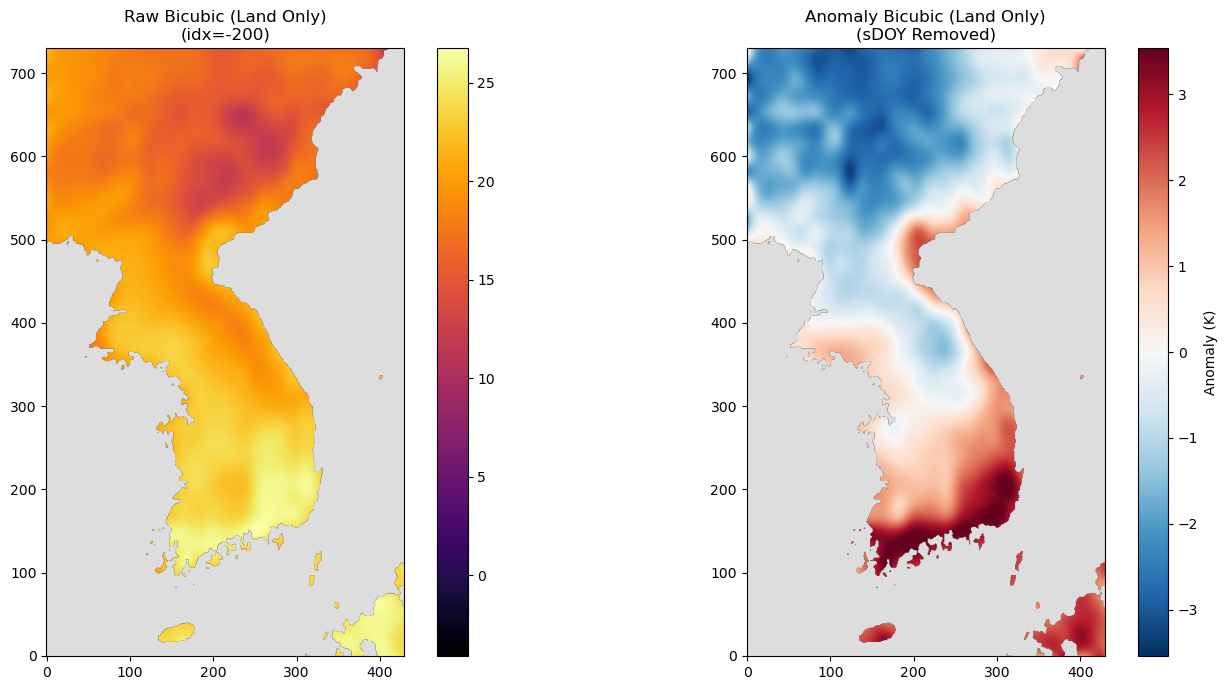

In [11]:
import torch
import matplotlib.pyplot as plt
import numpy as np
import os

# -------------------- 설정 --------------------
base_dir = "./Dataset/"
raw_path = os.path.join(base_dir, "ERA5_Bicubic_Raw.pt")
anom_path = os.path.join(base_dir, "ERA5_Bicubic_Anomaly.pt")
mask_path = "../Data/Dataset/LDAPS.land_mask_only.nc"

# 보고 싶은 시간 인덱스 (0부터 시작)
# 예: 0(첫날), 180(여름쯤), 365(1년 뒤)
TIME_IDX = -200

# -------------------- 데이터 로드 --------------------
print(f"📂 파일 로드 중...")
try:
    # 텐서 로드 및 numpy 변환
    raw_data = torch.load(raw_path)
    anom_data = torch.load(anom_path)
    
    # 마스크 로드 (1=Land, 0=Sea)
    ms = xr.open_dataset(mask_path)
    land_mask = np.squeeze(ms['mask'].values) # (731, 430)
    
    # 0(바다)을 NaN으로 변경 -> 그래프 그릴 때 투명하게 나옴
    # 1(육지)은 1로 유지
    mask_for_plot = np.where(land_mask == 1, 1.0, np.nan)
    
    print(f"✅ 데이터 Shape: {raw_data.shape}") # (Time, Y, X)
except FileNotFoundError:
    print("❌ 파일을 찾을 수 없습니다. 경로를 확인해주세요.")
    exit()

# -------------------- 특정 시간대 추출 --------------------
# (Y, X) 형태의 2D 이미지 한 장 꺼내기
img_raw = raw_data[TIME_IDX].numpy() - 273.15
img_anom = anom_data[TIME_IDX].numpy()
img_raw_masked = img_raw * mask_for_plot
img_anom_masked = img_anom * mask_for_plot

# -------------------- 통계 확인 (육지만) --------------------
print(f"\n📊 [Time Index: {TIME_IDX}] 육지 데이터 통계")
# np.nanmin/max는 NaN을 무시하고 진짜 값만 계산함
v_min = np.nanmin(img_anom_masked)
v_max = np.nanmax(img_anom_masked)
print(f"Anomaly (Land Only) | Min: {v_min:.2f}, Max: {v_max:.2f}, Mean: {np.nanmean(img_anom_masked):.2f}")

if v_min < -20:
    print("⚠️ 여전히 -20도 이하의 극단적인 값이 육지에 남아있습니다.")
else:
    print("✅ 극단적인 이상치가 사라졌습니다.")

# -------------------- 그리기 --------------------
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# 배경색을 회색으로 설정 (투명하게 뚫린 NaN 부분과 구별하기 위해)
for ax in axes:
    ax.set_facecolor('#dddddd')

# 1. Raw Data (Masked)
im1 = axes[0].imshow(img_raw_masked, cmap='inferno', origin='lower')
axes[0].set_title(f"Raw Bicubic (Land Only)\n(idx={TIME_IDX})")
plt.colorbar(im1, ax=axes[0], fraction=0.046, pad=0.04)

# 2. Anomaly Data (Masked)
# vmin, vmax를 육지 데이터의 실제 범위에 맞춰서 설정 (또는 -5 ~ +5 로 고정)
# 여기서는 육지 데이터의 99% 범위를 잡아서 이상치를 살짝 무시하고 그리는 기법 사용
robust_max = np.nanpercentile(np.abs(img_anom_masked), 99) # 상위 1% 이상치 제외
# robust_max가 너무 작으면 최소 3도로 설정
robust_max = max(robust_max, 3.0) 

im2 = axes[1].imshow(img_anom_masked, cmap='RdBu_r', origin='lower', vmin=-robust_max, vmax=robust_max)
axes[1].set_title(f"Anomaly Bicubic (Land Only)\n(sDOY Removed)")
plt.colorbar(im2, ax=axes[1], fraction=0.046, pad=0.04, label='Anomaly (K)')

plt.tight_layout()
plt.show()

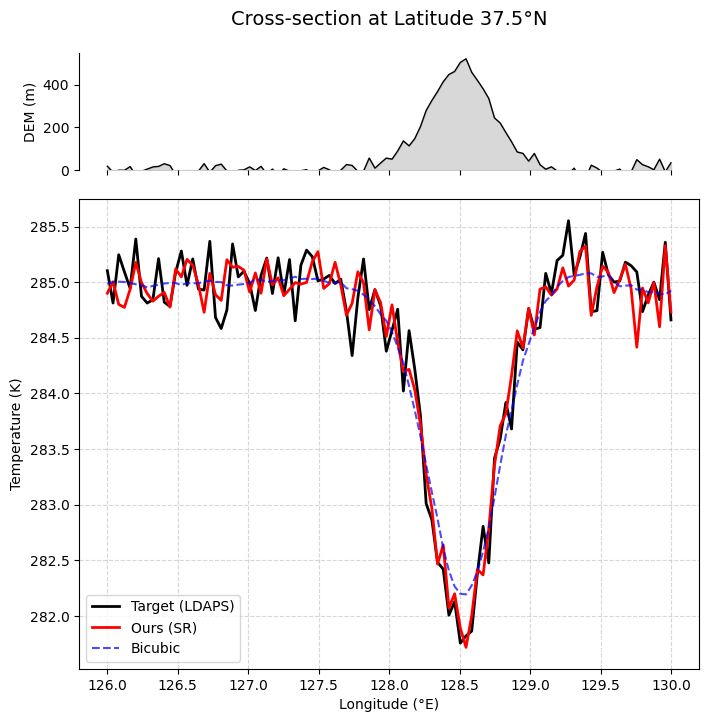

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# 1. 임의의 데이터 생성 (실제 데이터로 교체 필요)
lon = np.linspace(126, 130, 100)
# 지형 데이터 (태백산맥 모사)
dem = 500 * np.exp(-(lon - 128.5)**2 / 0.1) + 200 * np.random.normal(0, 0.1, 100)

target = 285 - (dem * 0.0065) + np.random.normal(0, 0.2, 100)
ours = 285 - (dem * 0.0065) + np.random.normal(0, 0.1, 100)
bicubic = 285 - (np.convolve(dem, np.ones(10)/10, mode='same') * 0.0065) # 뭉개진 예보

# 2. 시각화 설정
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 8), sharex=True, 
                             gridspec_kw={'height_ratios': [1, 4]})
plt.subplots_adjust(hspace=0.1)

# --- 상단: 지형(DEM) 프로파일 ---
ax1.fill_between(lon, 0, dem, color='gray', alpha=0.3, label='Terrain (DEM)')
ax1.plot(lon, dem, color='black', linewidth=1)
ax1.set_ylabel('DEM (m)')
ax1.set_ylim(0,)
ax1.set_title('Cross-section at Latitude 37.5°N', fontsize=14, pad=20)

ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.spines['bottom'].set_visible(False)

# --- 하단: 온도 프로파일 (Final Value) ---
ax2.plot(lon, target, color='black', label='Target (LDAPS)', linewidth=2)
ax2.plot(lon, ours, color='red', label='Ours (SR)', linewidth=2)
ax2.plot(lon, bicubic, color='blue', linestyle='--', label='Bicubic', alpha=0.7)

ax2.set_xlabel('Longitude (°E)')
ax2.set_ylabel('Temperature (K)')
ax2.grid(True, linestyle='--', alpha=0.5)
ax2.legend()


plt.show()